# Medical Insurance Cost Prediction — Machine Learning Case Study

**Case Study 14** · Medical Cost Personal Dataset · supervised **regression**

This notebook walks through the complete study reported in `docs/Medical_Insurance_Cost_Prediction_ML_Case_Study_Report.pdf`:

1. Load and document the dataset
2. Exploratory data analysis (target shape, group comparisons, interaction structure)
3. Preprocessing + feature engineering (`bmi×smoker`, `age×smoker`, `is_obese`)
4. Train and tune four regressors — MLR, Polynomial (deg 2), Decision Tree, Random Forest
5. Evaluate with R², MAE, MSE, RMSE, MAPE + residual and subgroup error analysis
6. Demonstrate prediction on unseen individuals

All numbers are reproducible with `RANDOM_STATE = 42`. The full pipeline (which also regenerates every figure and `results.json`) is `src/medical_insurance_ml.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
print("libraries loaded")

libraries loaded


## 1. Load the dataset

Medical Cost Personal Dataset (Kaggle: `mirichoi0218/insurance`), 1,338 rows, 7 columns, no missing values.

In [2]:
df_raw = pd.read_csv("data/insurance.csv")
print("shape:", df_raw.shape)
print("missing cells:", int(df_raw.isna().sum().sum()))
print("exact duplicate rows:", int(df_raw.duplicated().sum()))
df_raw.head()

shape: (1338, 7)
missing cells: 0
exact duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print("cleaned shape:", df.shape)
df.describe().round(2)

cleaned shape: (1337, 7)


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


## 2. Exploratory data analysis

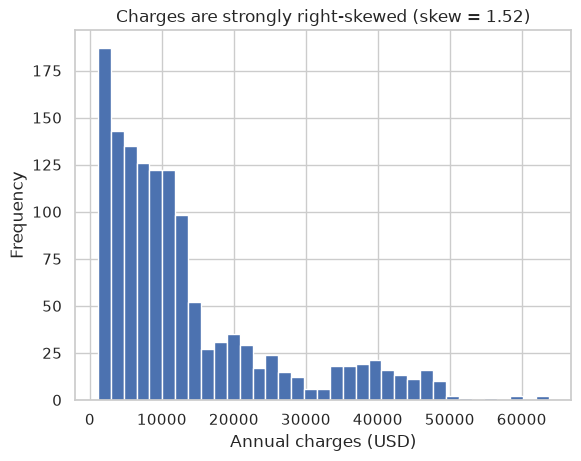

In [4]:
df["charges"].hist(bins=35, edgecolor="w")
plt.xlabel("Annual charges (USD)"); plt.ylabel("Frequency")
plt.title("Charges are strongly right-skewed (skew = %.2f)" % df["charges"].skew())
plt.show()

In [5]:
print("mean charges by smoking status:")
print(df.groupby("smoker")["charges"].mean().round(2))
print("\nmean charges by region:")
print(df.groupby("region")["charges"].mean().round(2))
print("\ncorrelation with the target:")
print(df[["age", "bmi", "children", "charges"]].corr()["charges"].round(4))

mean charges by smoking status:
smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64

mean charges by region:
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

correlation with the target:
age         0.2983
bmi         0.1984
children    0.0674
charges     1.0000
Name: charges, dtype: float64


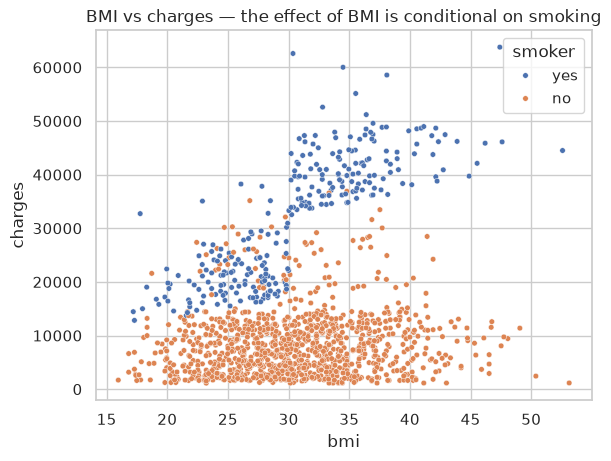

In [6]:
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", s=16)
plt.title("BMI vs charges — the effect of BMI is conditional on smoking")
plt.show()

### The key interaction

Going from normal to obese BMI raises mean charges far more for smokers than non-smokers. This motivates the engineered interaction features.

In [7]:
bmi_cat = pd.cut(df.bmi, [0, 18.5, 25, 30, 100], labels=["Under", "Normal", "Over", "Obese"])
pivot = df.groupby(["smoker", bmi_cat], observed=True)["charges"].mean().unstack().round(2)
print(pivot)
print("\ndelta Normal -> Obese:")
print((pivot["Obese"] - pivot["Normal"]).round(2))

bmi        Under    Normal      Over     Obese
smoker                                        
no       5485.06   7734.65   8226.09   8866.16
yes     18809.82  19942.22  22491.18  41692.81

delta Normal -> Obese:
smoker
no      1131.51
yes    21750.59
dtype: float64


## 3. Preprocessing and feature engineering

In [8]:
data = df.copy()
data["sex"] = data["sex"].map({"female": 0, "male": 1})
data["smoker"] = data["smoker"].map({"no": 0, "yes": 1})
data = pd.get_dummies(data, columns=["region"], drop_first=True, dtype=int)

data["bmi_smoker_interaction"] = data["bmi"] * data["smoker"]
data["age_smoker_interaction"] = data["age"] * data["smoker"]
data["is_obese"] = (data["bmi"] >= 30).astype(int)

X = data.drop(columns=["charges"])
y = data["charges"]
print("features (%d):" % X.shape[1], list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.20, random_state=RANDOM_STATE)
print("train/val/test:", len(X_tr), len(X_val), len(X_test))

features (11): ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_smoker_interaction', 'age_smoker_interaction', 'is_obese']
train/val/test: 855 214 268


## 4. Models

All preprocessing that learns from data stays **inside** the pipeline so it is fitted on training folds only (no leakage).

In [9]:
def metrics(y_true, y_pred):
    return {
        "R2": round(r2_score(y_true, y_pred), 4),
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "MSE": round(mean_squared_error(y_true, y_pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        "MAPE_pct": round(100 * mean_absolute_percentage_error(y_true, y_pred), 2),
    }

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, preds = {}, {}

### 4.1 Multiple linear regression (interpretable baseline)

In [10]:
Xb = df[["age", "bmi", "children"]].copy()
Xb["sex"] = (df["sex"] == "male").astype(int)
Xb["smoker"] = (df["smoker"] == "yes").astype(int)
Xb = pd.concat([Xb, pd.get_dummies(df["region"], prefix="region", drop_first=True, dtype=int)], axis=1)

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, y, test_size=0.20, random_state=RANDOM_STATE)
mlr = LinearRegression().fit(Xb_tr, yb_tr)
p_mlr = mlr.predict(Xb_te)

results["Multiple Linear Regression"] = metrics(yb_te, p_mlr)
preds["Multiple Linear Regression"] = (yb_te, p_mlr)
print("coefficients (USD per unit change):")
for k, v in sorted(zip(Xb.columns, mlr.coef_), key=lambda t: -abs(t[1])):
    print(f"  {k:20s} {v:12,.2f}")
print("intercept:", round(mlr.intercept_, 2))

coefficients (USD per unit change):
  smoker                  23,077.76
  region_southeast          -838.92
  region_southwest          -659.14
  children                   533.01
  region_northwest          -391.76
  bmi                        318.70
  age                        248.21
  sex                       -101.54
intercept: -11092.65


### 4.2 Polynomial regression, degree 2 (expansion + scaling + Ridge)

In [11]:
poly_pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
])
poly_pipe.fit(X_tr, y_tr)
p_poly = poly_pipe.predict(X_test)
results["Polynomial Regression (deg 2)"] = metrics(y_test, p_poly)
preds["Polynomial Regression (deg 2)"] = (y_test, p_poly)
print("expanded feature count:", poly_pipe.named_steps["poly"].n_output_features_)

expanded feature count: 77


### 4.3 Decision tree (tuned by 5-fold grid search)

In [12]:
dt_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    {"max_depth": [3, 4, 5, 6, 8, 10, 12, None],
     "min_samples_leaf": [1, 2, 3, 5, 10, 20],
     "min_samples_split": [2, 5, 10, 20]},
    cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
dt_search.fit(X_tr, y_tr)
dt = dt_search.best_estimator_
p_dt = dt.predict(X_test)
results["Decision Tree Regression"] = metrics(y_test, p_dt)
preds["Decision Tree Regression"] = (y_test, p_dt)
print("best params:", dt_search.best_params_)
print("depth / leaves:", dt.get_depth(), dt.get_n_leaves())

best params: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 20}
depth / leaves: 5 21


### 4.4 Random forest (tuned by 5-fold grid search)

In [13]:
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    {"n_estimators": [200, 400], "max_depth": [6, 10, 15, None],
     "min_samples_leaf": [1, 2, 3, 5], "max_features": ["sqrt", 1.0]},
    cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_search.fit(X_tr, y_tr)
rf = rf_search.best_estimator_
p_rf = rf.predict(X_test)
results["Random Forest Regression"] = metrics(y_test, p_rf)
preds["Random Forest Regression"] = (y_test, p_rf)
print("best params:", rf_search.best_params_)

best params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 200}


## 5. Results

In [14]:
table = pd.DataFrame(results).T[["R2", "MAE", "MSE", "RMSE", "MAPE_pct"]]
table.columns = ["R2", "MAE (USD)", "MSE (USD^2)", "RMSE (USD)", "MAPE (%)"]
table.round(2)

,R2,MAE (USD),MSE (USD^2),RMSE (USD),MAPE (%)
Multiple Linear Regression,0.81,4177.05,35478020.68,5956.34,41.40
Polynomial Regression (deg 2),0.90,2353.50,17798941.23,4218.88,30.08
Decision Tree Regression,0.89,2649.80,19429611.74,4407.90,33.50
Random Forest Regression,0.90,2435.54,19068226.55,4366.72,35.29


In [15]:
best_name = table["RMSE (USD)"].idxmin()
print("best model:", best_name)
print(table.loc[best_name].round(3).to_string())

best model: Polynomial Regression (deg 2)
R2             9.030000e-01
MAE (USD)      2.353500e+03
MSE (USD^2)    1.779894e+07
RMSE (USD)     4.218880e+03
MAPE (%)       3.008000e+01


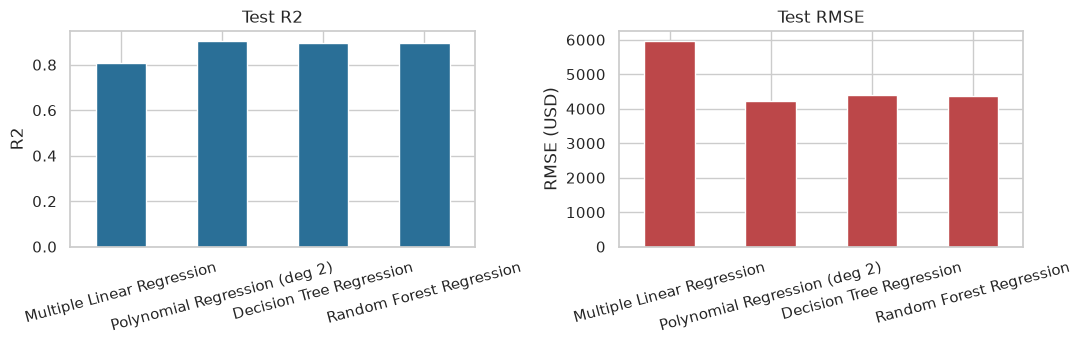

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
table["R2"].plot.bar(ax=ax[0], color="#2a6f97", rot=15); ax[0].set_ylabel("R2"); ax[0].set_title("Test R2")
table["RMSE (USD)"].plot.bar(ax=ax[1], color="#bc4749", rot=15); ax[1].set_ylabel("RMSE (USD)"); ax[1].set_title("Test RMSE")
plt.tight_layout(); plt.show()

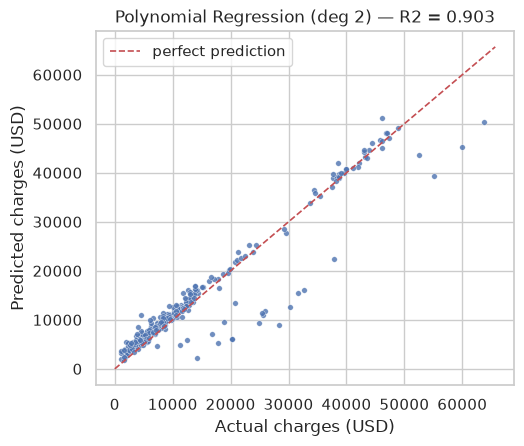

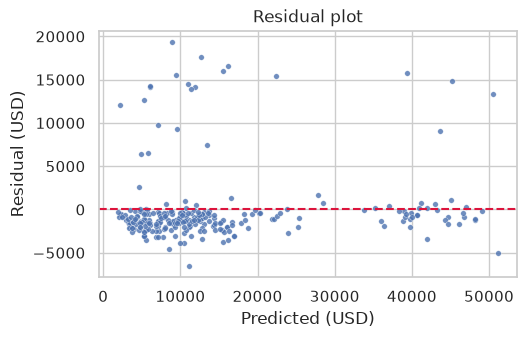

In [17]:
yt, yp = preds[best_name]
plt.figure(figsize=(5.4, 4.6))
plt.scatter(yt, yp, s=16, alpha=.8, edgecolor="w", linewidth=.3)
lim = [0, max(yt.max(), yp.max()) * 1.03]
plt.plot(lim, lim, "r--", lw=1.2, label="perfect prediction")
plt.xlabel("Actual charges (USD)"); plt.ylabel("Predicted charges (USD)")
plt.title(f"{best_name} — R2 = {r2_score(yt, yp):.3f}"); plt.legend(); plt.show()

resid = yt - yp
plt.figure(figsize=(5.4, 3.2))
plt.scatter(yp, resid, s=16, alpha=.8, edgecolor="w", linewidth=.3)
plt.axhline(0, color="crimson", ls="--"); plt.xlabel("Predicted (USD)"); plt.ylabel("Residual (USD)")
plt.title("Residual plot"); plt.show()

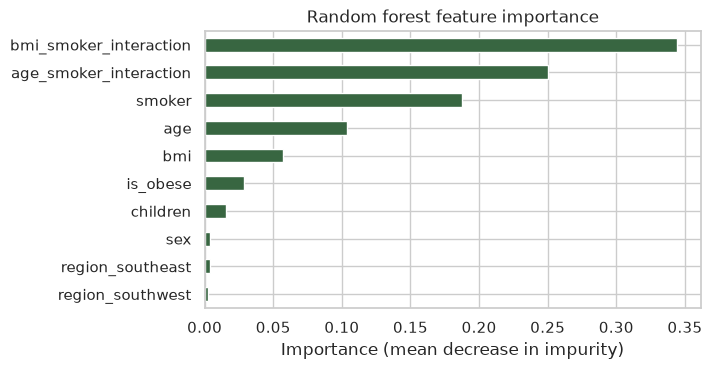

In [18]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)
imp.tail(10).plot.barh(color="#386641", figsize=(6.4, 3.6))
plt.xlabel("Importance (mean decrease in impurity)")
plt.title("Random forest feature importance"); plt.show()

In [19]:
# subgroup error analysis: is the model equally reliable for smokers and non-smokers?
err = pd.DataFrame({"actual": np.asarray(yt), "pred": np.asarray(yp)})
err["smoker"] = df.loc[yt.index, "smoker"].values
err["abs_err"] = (err.actual - err.pred).abs()
print("mean absolute error by smoking status (USD):")
print(err.groupby("smoker")["abs_err"].mean().round(2))

mean absolute error by smoking status (USD):
smoker
no     2364.47
yes    2315.48
Name: abs_err, dtype: float64


## 6. Sample predictions

Five held-out test records, then three hypothetical applicants that never appear in the data.

In [20]:
rows = []
for idx in y_test.index[:5]:
    row = df.loc[idx]
    pred = rf.predict(X.loc[[idx]])[0]
    rows.append({"age": row.age, "sex": row.sex, "bmi": row.bmi, "children": row.children,
                 "smoker": row.smoker, "region": row.region,
                 "actual": round(row.charges, 2), "predicted": round(float(pred), 2),
                 "error": round(float(pred) - row.charges, 2)})
pd.DataFrame(rows)

,age,sex,bmi,children,smoker,region,actual,predicted,error
0,49,male,22.515,0,no,northeast,8688.86,10229.17,1540.31
1,29,female,25.600,4,no,southwest,5708.87,7744.87,2036.00
2,51,female,36.385,3,no,northwest,11436.74,11612.10,175.36
3,31,male,34.390,3,yes,northwest,38746.36,39824.07,1077.72
4,31,male,38.390,2,no,southeast,4463.21,6131.07,1667.86


In [21]:
raw = pd.DataFrame([
    {"age": 24, "sex": 0, "bmi": 22.5, "children": 0, "smoker": 0, "region_southwest": 1},
    {"age": 45, "sex": 1, "bmi": 34.8, "children": 2, "smoker": 1},
    {"age": 60, "sex": 1, "bmi": 28.1, "children": 3, "smoker": 0, "region_southeast": 1},
]).fillna(0)

raw["bmi_smoker_interaction"] = raw["bmi"] * raw["smoker"]
raw["age_smoker_interaction"] = raw["age"] * raw["smoker"]
raw["is_obese"] = (raw["bmi"] >= 30).astype(int)

new = raw.reindex(columns=X.columns, fill_value=0)
new["predicted_charges_usd"] = rf.predict(new[X.columns]).round(2)
new[["age", "sex", "bmi", "children", "smoker", "is_obese", "predicted_charges_usd"]]

,age,sex,bmi,children,smoker,is_obese,predicted_charges_usd
0,24,0,22.5,0,0,0,4550.53
1,45,1,34.8,2,1,1,42239.44
2,60,1,28.1,3,0,0,13671.23


## 7. Conclusion

- Non-linear, interaction-aware models clearly beat additive linear regression (R² 0.807 → 0.903).
- Degree-2 polynomial regression with L2 regularisation is the best model; the tuned random forest is a close second.
- The BMI×smoker and age×smoker interactions plus the smoking flag carry almost all predictive power; sex and region are negligible.
- Remaining error is concentrated among low-cost non-smokers, i.e. it is a **data** limitation (no clinical or claims-history variables), not an algorithmic one.

See `docs/` for the full written report.